# Uplift Modeling and Heterogeneous Treatment Effects

**What you'll learn**

- Why "target the customers most likely to buy" is the wrong objective: response probability $P(\text{buy}\mid T{=}1, x)$ vs uplift $\tau(x) = P(\text{buy}\mid T{=}1,x) - P(\text{buy}\mid T{=}0,x)$, demonstrated on a simulation with the four classic segments (persuadables, sure things, lost causes, sleeping dogs).
- S-, T-, and X-learners built on LightGBM, trained on randomized-experiment data and scored against the *known* CATE — including where each meta-learner's bias comes from.
- How to evaluate an uplift model when no individual's treatment effect is ever observed: uplift decile charts, Qini and uplift curves, AUUC — all implemented from scratch — and a demonstration that ordinary AUC is the wrong metric.
- The overfitting trap specific to uplift: learners happily "discover" segments in data with **no** heterogeneity, and only honest out-of-sample Qini catches it.
- Turning scores into money: expected profit of treating the top-$k\%$ under a treatment cost, choosing $k$, and off-policy (IPS) evaluation of the resulting policy from the randomized holdout.
- Where uplift modeling sits in the wider toolkit: data requirements, sample-size hunger, and the connection to contextual bandits.

**Why it matters in interviews**

- "We have a discount budget — who should get it?" is a staple senior-DS case at any company with promotions, retention offers, or ads. The expected answer is uplift, not response, and interviewers probe whether you know the difference *quantitatively*.
- "How would you evaluate this model offline, given that you never observe an individual's counterfactual?" is the standard depth probe; Qini/AUUC from scratch is a strong signal.
- Critiquing "marketing wants to target likely buyers" is a classic judgment question: the senior answer names sure things (wasted spend) *and* sleeping dogs (negative effects), then proposes the experiment + uplift pipeline.

This notebook assumes the causal basics from
[01_potential_outcomes_dags.ipynb](01_potential_outcomes_dags.ipynb) (potential outcomes,
why randomization identifies effects) and uses estimation ideas from
[02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb) when data
are not randomized. Here the treatment is randomized — the modeling question is
**who benefits, not whether it works on average**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from scipy.special import expit, logit
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)  # master generator: population, experiment, split
# Side experiments (pitfalls, exercises) use their own explicitly-seeded generators so
# each is reproducible in isolation and robust to cell reordering during editing.

plt.rcParams.update({
    "figure.figsize": (9.0, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SEGMENTS = ["persuadable", "sure thing", "lost cause", "sleeping dog"]
SEG_COLORS = {"persuadable": "tab:green", "sure thing": "tab:blue",
              "lost cause": "tab:gray", "sleeping dog": "tab:red"}

## 1. The setting: a discount campaign and the four segments

An e-commerce business can send a **\$5-off voucher** ahead of next month. The outcome is
`buy` — does the customer place an order in the next 30 days? Every customer has two
potential conversion probabilities:

- $p_0(x) = P(\text{buy} \mid T{=}0, x)$ — would they buy *without* the voucher?
- $p_1(x) = P(\text{buy} \mid T{=}1, x)$ — would they buy *with* it?

The **uplift / CATE** is $\tau(x) = p_1(x) - p_0(x)$, and the $(p_0, p_1)$ plane defines
the four classic segments:

| segment | behavior | $\tau$ |
|---|---|---|
| **persuadable** | buys only if treated | $> 0$ |
| **sure thing** | buys either way | $\approx 0$ |
| **lost cause** | buys neither way | $\approx 0$ |
| **sleeping dog** | *stops* buying if treated | $< 0$ |

Sleeping dogs are not a theoretical curiosity: discounts can cheapen a premium brand,
trigger comparison shopping, or (in retention settings) remind a passive subscriber to
cancel. In our simulation they are **premium customers with low discount affinity**.

The simulation uses realistic CRM covariates — recency, order frequency, basket size, app
sessions, tenure, historical discount affinity, premium flag. Baseline conversion $p_0$
is logistic in engagement; uplift has a persuadable component (largest for
discount-affine customers with mid-range $p_0$) and a sleeping-dog component (premium,
low-affinity, high-ish $p_0$). Because we simulate, every customer carries oracle columns
(`p0`, `p1`, `tau`, `segment`) that a real analyst never sees — the ground truth every
method is scored against.

In [2]:
X_COLS = ["recency_days", "orders_12m", "avg_basket", "sessions_wk",
          "tenure_m", "discount_affinity", "premium"]


def make_population(n, rng, heterogeneity=True):
    """Simulate a customer base with known p0(x), p1(x), tau(x).

    heterogeneity=False gives a flat tau = +0.04 for everyone (used in the pitfalls
    section to show learners inventing segments out of noise).
    """
    recency = rng.gamma(2.0, 18.0, n)                       # days since last order
    orders = rng.poisson(rng.gamma(2.0, 1.2, n))            # orders in last 12 months
    log_basket = 3.0 + 0.45 * rng.normal(0.0, 1.0, n)
    avg_basket = np.exp(log_basket)                         # $ per order
    sessions = rng.gamma(2.0, 1.5, n)                       # app sessions / week
    tenure = rng.uniform(1.0, 48.0, n)                      # months as customer
    aff = rng.beta(2.0, 3.5, n)                             # share of past orders on promo
    premium = rng.binomial(1, expit(-1.1 + 1.3 * (log_basket - 3.0)))

    logit_p0 = (-1.6 + 0.40 * sessions - 0.022 * recency + 0.35 * np.log1p(orders)
                + 0.80 * premium + 0.006 * tenure)
    p0 = expit(logit_p0)

    if heterogeneity:
        # persuadable lift: discount-affine customers who are neither hopeless nor certain
        lift = 0.55 * aff ** 2 * np.exp(-0.5 * ((p0 - 0.28) / 0.16) ** 2)
        # sleeping dogs: premium, low-affinity customers put off by the voucher
        dog = -0.30 * premium * (1.0 - aff) ** 2 * expit((p0 - 0.40) * 10.0)
        p1 = np.clip(p0 + lift + dog, 0.002, 0.985)
    else:
        p1 = np.clip(p0 + 0.04, 0.002, 0.985)
    tau = p1 - p0

    segment = np.select(
        [tau > 0.05, tau < -0.05, p0 >= 0.45],
        ["persuadable", "sleeping dog", "sure thing"], default="lost cause")

    return pd.DataFrame({
        "recency_days": recency, "orders_12m": orders, "avg_basket": avg_basket,
        "sessions_wk": sessions, "tenure_m": tenure, "discount_affinity": aff,
        "premium": premium,
        # oracle columns (exist only because we simulated):
        "p0": p0, "p1": p1, "tau": tau, "segment": segment,
    })


def run_rct(pop, rng, p_treat=0.5):
    """Randomize treatment and draw the single observed outcome per customer."""
    t = rng.binomial(1, p_treat, len(pop))
    p = np.where(t == 1, pop["p1"].to_numpy(), pop["p0"].to_numpy())
    out = pop.copy()
    out["treated"] = t
    out["buy"] = (rng.random(len(pop)) < p).astype(int)
    return out


pop = make_population(60_000, rng)
seg_tab = (pop.groupby("segment")[["p0", "p1", "tau"]].mean()
           .assign(share=pop["segment"].value_counts(normalize=True))
           .loc[SEGMENTS])
print(f"n = {len(pop):,}   true ATE = {pop['tau'].mean():+.4f}")
print(seg_tab.round(3).to_string())

n = 60,000   true ATE = +0.0313
                p0    p1    tau  share
segment                               
persuadable  0.287 0.411  0.124  0.341
sure thing   0.633 0.639  0.006  0.215
lost cause   0.253 0.271  0.018  0.306
sleeping dog 0.628 0.499 -0.129  0.138


The average effect is positive — a plain A/B test would call this campaign a win — but
the average hides the structure: a persuadable minority carries all the gains, most
customers are unmoved, and a sleeping-dog minority is actively harmed. The $(p_0, p_1)$
scatter makes the geometry explicit.

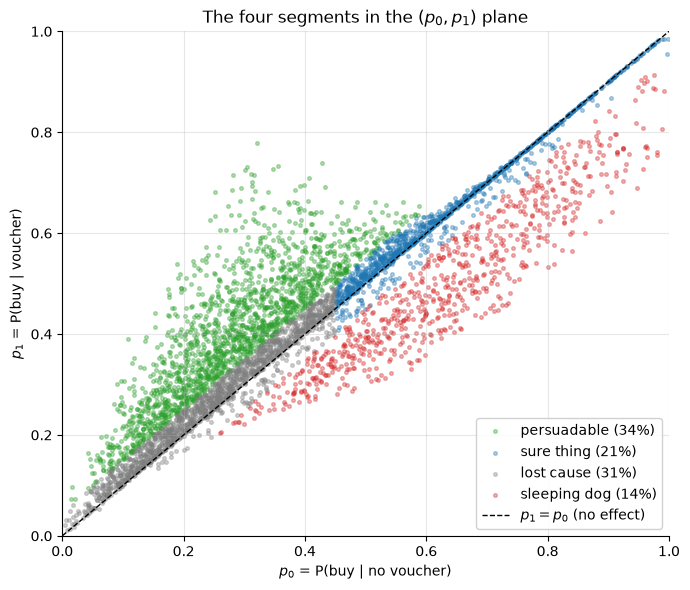

In [3]:
show = pop.sample(5_000, random_state=42)
fig, ax = plt.subplots(figsize=(7.0, 6.0))
for seg in SEGMENTS:
    d = show[show["segment"] == seg]
    ax.scatter(d["p0"], d["p1"], s=7, alpha=0.35, color=SEG_COLORS[seg],
               label=f"{seg} ({seg_tab.loc[seg, 'share']:.0%})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="$p_1 = p_0$ (no effect)")
ax.set(xlim=(0, 1), ylim=(0, 1),
       xlabel="$p_0$ = P(buy | no voucher)", ylabel="$p_1$ = P(buy | voucher)",
       title="The four segments in the $(p_0, p_1)$ plane")
ax.legend(loc="lower right", framealpha=0.9)
plt.tight_layout()
plt.show()

Now run the experiment the way a real team would: **randomize the voucher 50/50**, observe
one outcome per customer, and split into a training half and a held-out evaluation half.
The difference in means recovers the ATE (that machinery is
[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb));
everything after this cell is about going *beyond* the average.

In [4]:
df = run_rct(pop, rng)
perm = rng.permutation(len(df))
train = df.iloc[perm[:30_000]].reset_index(drop=True)
test = df.iloc[perm[30_000:]].reset_index(drop=True)
n_test = len(test)
y_te = test["buy"].to_numpy()
t_te = test["treated"].to_numpy()

dim = (df.loc[df["treated"] == 1, "buy"].mean()
       - df.loc[df["treated"] == 0, "buy"].mean())
se = np.sqrt(sum(df.loc[df["treated"] == g, "buy"].var(ddof=1)
                 / (df["treated"] == g).sum() for g in (0, 1)))
print(f"diff-in-means ATE: {dim:+.4f} (95% CI {dim - 1.96 * se:+.4f} .. {dim + 1.96 * se:+.4f})")
print(f"true ATE         : {df['tau'].mean():+.4f}")

diff-in-means ATE: +0.0382 (95% CI +0.0303 .. +0.0461)
true ATE         : +0.0313


## 2. Response-model targeting vs uplift targeting

The traditional playbook — still the default in many marketing teams — is a **response
model**: train $\hat{P}(\text{buy} \mid T{=}1, x)$ on the treated arm (or on last
quarter's buyers) and mail the top of that ranking. It answers *"who buys when treated?"*
— but the campaign's incremental value is $\sum_{i \in \text{targeted}} \tau_i$, and
$p_1$ ranks sure things (high $p_1$, $\tau \approx 0$) at the very top. Sleeping dogs
also have respectable $p_1$, so a response ranking never learns to avoid them.

We give the response model every advantage: a well-tuned LightGBM trained on the 15k
treated training customers. Then we compare targeting the top 30% by $\hat{p}_1$ against
targeting the top 30% by *true* uplift (the oracle ceiling — learned uplift models come
next), scoring both with the true $\tau$ on the held-out half.

In [5]:
def new_clf(seed=42):
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              min_child_samples=200, random_state=seed,
                              n_jobs=1, verbose=-1)


def new_reg(seed=42):
    return lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                             min_child_samples=200, random_state=seed,
                             n_jobs=1, verbose=-1)


resp_model = new_clf().fit(train.loc[train["treated"] == 1, X_COLS],
                           train.loc[train["treated"] == 1, "buy"])
p1_resp = resp_model.predict_proba(test[X_COLS])[:, 1]

budget = 0.30
k30 = int(budget * n_test)
policies = {
    "response: top 30% by P(buy|T=1)": np.argsort(-p1_resp, kind="stable")[:k30],
    "uplift (oracle): top 30% by tau": np.argsort(-test["tau"].to_numpy(), kind="stable")[:k30],
    "random 30%": np.random.default_rng(4).permutation(n_test)[:k30],
}

rows = []
for name, idx in policies.items():
    sel = test.iloc[idx]
    comp = sel["segment"].value_counts(normalize=True)
    rows.append({"policy": name,
                 "incr. buys /10k customers": sel["tau"].sum() / n_test * 10_000,
                 **{s: comp.get(s, 0.0) for s in SEGMENTS}})
pol_tab = pd.DataFrame(rows).set_index("policy")
print(pol_tab.round(3).to_string())

resp_sel = test.iloc[policies["response: top 30% by P(buy|T=1)"]]
dogs = resp_sel[resp_sel["segment"] == "sleeping dog"]
sure = resp_sel[resp_sel["segment"] == "sure thing"]
print(f"\nresponse-targeted set: {len(sure):,} sure things ({len(sure) / k30:.0%}) "
      f"with mean tau {sure['tau'].mean():+.3f} -> pure budget waste")
print(f"response-targeted set: {len(dogs):,} sleeping dogs ({len(dogs) / k30:.0%}) "
      f"whose combined true uplift is {dogs['tau'].sum():+,.0f} purchases -> backfire")

                                 incr. buys /10k customers  persuadable  sure thing  lost cause  sleeping dog
policy                                                                                                       
response: top 30% by P(buy|T=1)                     66.323        0.268       0.526       0.025         0.181
uplift (oracle): top 30% by tau                    403.510        1.000       0.000       0.000         0.000
random 30%                                          98.419        0.350       0.213       0.301         0.136

response-targeted set: 4,734 sure things (53%) with mean tau +0.005 -> pure budget waste
response-targeted set: 1,628 sleeping dogs (18%) whose combined true uplift is -212 purchases -> backfire


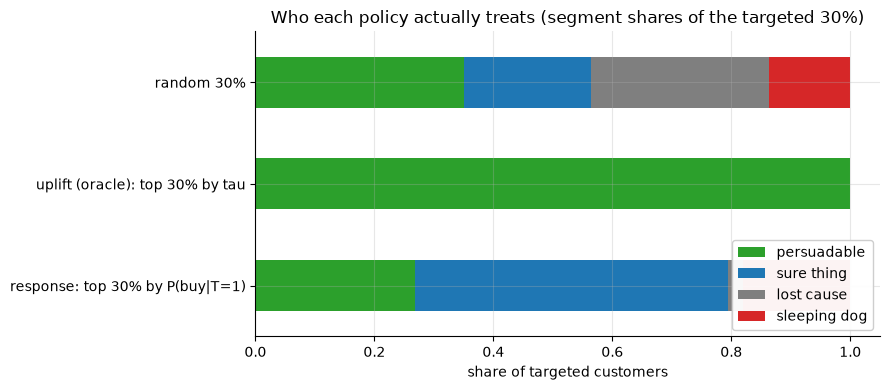

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
pol_tab[SEGMENTS].plot(kind="barh", stacked=True, ax=ax,
                       color=[SEG_COLORS[s] for s in SEGMENTS])
ax.set(title="Who each policy actually treats (segment shares of the targeted 30%)",
       xlabel="share of targeted customers", ylabel="")
ax.legend(loc="lower right", framealpha=0.95)
plt.tight_layout()
plt.show()

The response ranking fills the budget with sure things and a near-random dose of sleeping
dogs; uplift targeting concentrates on persuadables and avoids dogs almost entirely. Same
budget, radically different incremental sales — and the response policy *destroys* some
sales it would otherwise have had. This is the core interview point: **response models
rank by outcome level, campaigns pay off by outcome difference.**

## 3. Meta-learners: S, T, and X with LightGBM

A meta-learner turns any supervised learner into a CATE estimator. With randomized
treatment (propensity $e(x) = 0.5$ known):

- **S-learner** ("single"): fit $\hat\mu(x, t)$ with $t$ as one more feature;
  $\hat\tau(x) = \hat\mu(x,1) - \hat\mu(x,0)$. One model, maximal pooling — but
  regularization can *shrink the treatment splits away*, biasing $\hat\tau$ toward 0
  (trees only split on $t$ if it beats every covariate on gain).
- **T-learner** ("two"): fit $\hat\mu_1$ on the treated arm, $\hat\mu_0$ on control;
  $\hat\tau = \hat\mu_1 - \hat\mu_0$. No shrinkage of the effect, but the difference of
  two independently regularized models inherits *both* models' errors — noisy, and each
  arm's model wastes data relearning structure common to both arms.
- **X-learner** (Künzel et al. 2019): start from the T-learner arm models, then
  (1) impute individual effects $D^1_i = Y_i - \hat\mu_0(x_i)$ for treated and
  $D^0_i = \hat\mu_1(x_i) - Y_i$ for controls, (2) regress the imputed effects on $x$
  to get $\hat\tau_1(x), \hat\tau_0(x)$, (3) blend
  $\hat\tau(x) = e(x)\,\hat\tau_0(x) + (1 - e(x))\,\hat\tau_1(x)$. The second-stage
  regression models $\tau(x)$ *directly* — usually a much smoother target than
  $\mu(x)$ — and the propensity blend shines with imbalanced arms (Exercise 2).

Production-grade evolutions (R-learner, DR-learner, causal forests — in `EconML` /
`CausalML`) add orthogonalization and honesty guarantees; the meta-learner logic below is
what interviews expect you to produce from scratch.

In [7]:
# --- S-learner ---
Xs_tr = train[X_COLS].copy()
Xs_tr["treated"] = train["treated"]
s_model = new_clf().fit(Xs_tr, train["buy"])

X1 = test[X_COLS].copy(); X1["treated"] = 1
X0 = test[X_COLS].copy(); X0["treated"] = 0
tau_s = s_model.predict_proba(X1)[:, 1] - s_model.predict_proba(X0)[:, 1]

# --- T-learner ---
tr1 = train["treated"] == 1
mu1 = new_clf().fit(train.loc[tr1, X_COLS], train.loc[tr1, "buy"])
mu0 = new_clf().fit(train.loc[~tr1, X_COLS], train.loc[~tr1, "buy"])
tau_t = mu1.predict_proba(test[X_COLS])[:, 1] - mu0.predict_proba(test[X_COLS])[:, 1]

# --- X-learner (reuses the T-learner arm models as stage 1) ---
d1 = train.loc[tr1, "buy"].to_numpy() - mu0.predict_proba(train.loc[tr1, X_COLS])[:, 1]
d0 = mu1.predict_proba(train.loc[~tr1, X_COLS])[:, 1] - train.loc[~tr1, "buy"].to_numpy()
tau1_m = new_reg().fit(train.loc[tr1, X_COLS], d1)
tau0_m = new_reg().fit(train.loc[~tr1, X_COLS], d0)
e_x = 0.5  # known randomization propensity
tau_x = e_x * tau0_m.predict(test[X_COLS]) + (1 - e_x) * tau1_m.predict(test[X_COLS])

tau_true = test["tau"].to_numpy()
learners = {"S-learner": tau_s, "T-learner": tau_t, "X-learner": tau_x}

mse_tab = pd.DataFrame([
    {"learner": name,
     "MSE vs true tau": np.mean((th - tau_true) ** 2),
     "corr with true tau": np.corrcoef(th, tau_true)[0, 1],
     "mean tau-hat": th.mean()}
    for name, th in learners.items()
] + [{"learner": "constant ATE baseline",
      "MSE vs true tau": np.var(tau_true),
      "corr with true tau": np.nan, "mean tau-hat": tau_true.mean()}]
).set_index("learner")
print(mse_tab.round(4).to_string())

                       MSE vs true tau  corr with true tau  mean tau-hat
learner                                                                 
S-learner                        0.002               0.868         0.039
T-learner                        0.014               0.632         0.041
X-learner                        0.008               0.713         0.042
constant ATE baseline            0.009                 NaN         0.032


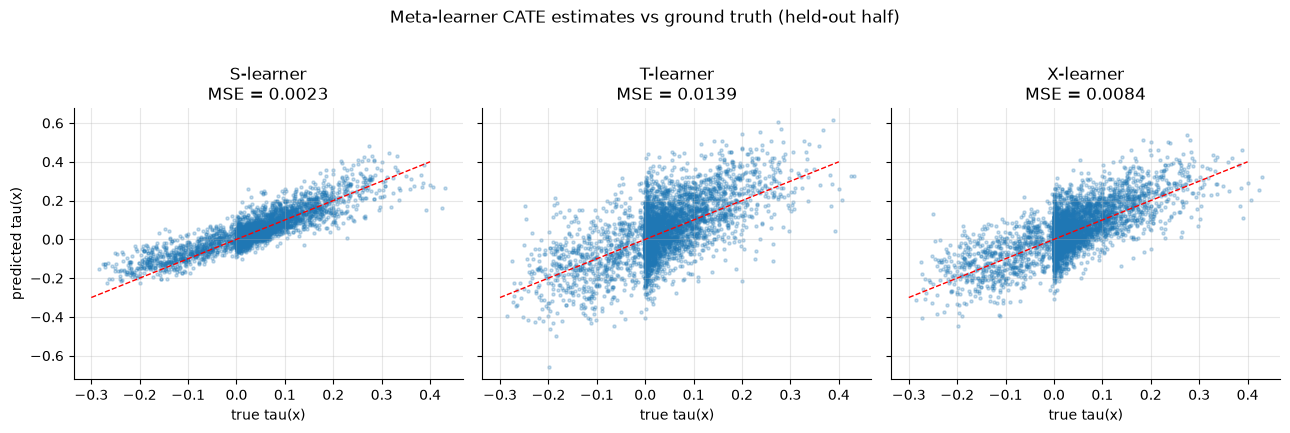

In [8]:
sample_idx = np.random.default_rng(2).choice(n_test, 4_000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, (name, th) in zip(axes, learners.items()):
    ax.scatter(tau_true[sample_idx], th[sample_idx], s=5, alpha=0.25)
    ax.plot([-0.3, 0.4], [-0.3, 0.4], "r--", lw=1)
    ax.set(title=f"{name}\nMSE = {mse_tab.loc[name, 'MSE vs true tau']:.4f}",
           xlabel="true tau(x)")
axes[0].set_ylabel("predicted tau(x)")
fig.suptitle("Meta-learner CATE estimates vs ground truth (held-out half)", y=1.02)
plt.tight_layout()
plt.show()

All three learners clearly beat the constant-ATE baseline: real heterogeneity is
recoverable from a 30k-customer experiment. The scatter plots show each learner's
signature failure: the S-learner is visibly *attenuated* (slope < 1 — regularization
swallowed part of the treatment signal), the T-learner tracks the truth but with the
widest scatter (two models' noise), and the X-learner's direct-on-$\tau$ second stage is
the smoothest. The exact ordering is problem-specific — with heavily imbalanced arms the
gap widens in X's favor (Exercise 2), and with tiny data all of them collapse
(Section 6.3).

## 4. Evaluating an uplift model without individual ground truth

In production there is no `tau` column — no customer ever reveals both potential
outcomes (the fundamental problem of causal inference). Everything above used oracle
access; real evaluation must reconstruct group-level counterfactuals from the
**randomized holdout**: within any subset chosen by $x$ (e.g. a score decile), treated
vs control difference in means is an unbiased uplift estimate for that subset.

**Uplift decile chart.** Split the holdout into deciles of predicted uplift; in each,
compute observed uplift $\bar{y}_{t} - \bar{y}_{c}$. A good model produces a steep,
monotone gradient. Overlaying mean *predicted* uplift per decile turns it into a
calibration check as well (the uplift analogue of
[../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb)).

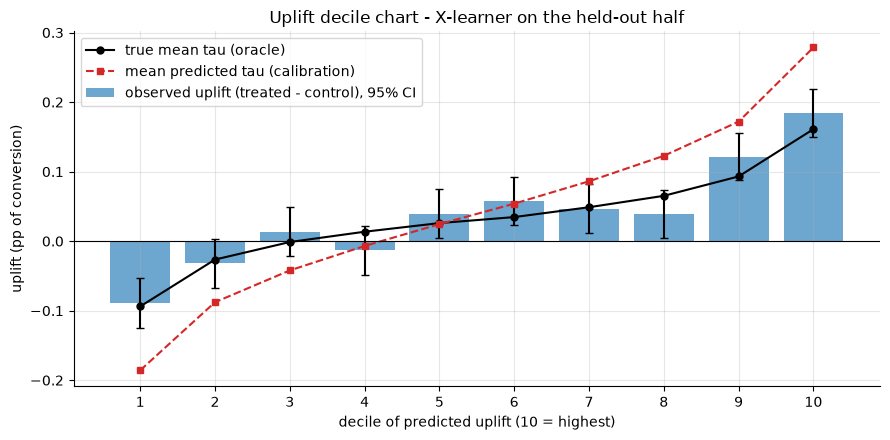

In [9]:
dtab = test.assign(decile=pd.qcut(tau_x, 10, labels=False) + 1, tau_hat=tau_x)
rates = dtab.pivot_table(index="decile", columns="treated", values="buy", aggfunc="mean")
counts = dtab.pivot_table(index="decile", columns="treated", values="buy", aggfunc="count")
obs_up = rates[1] - rates[0]
se_up = np.sqrt(rates[1] * (1 - rates[1]) / counts[1]
                + rates[0] * (1 - rates[0]) / counts[0])
true_up = dtab.groupby("decile")["tau"].mean()
pred_up = dtab.groupby("decile")["tau_hat"].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(obs_up.index, obs_up, yerr=1.96 * se_up, capsize=3, alpha=0.65,
       label="observed uplift (treated - control), 95% CI")
ax.plot(true_up.index, true_up, "ko-", ms=5, label="true mean tau (oracle)")
ax.plot(pred_up.index, pred_up, "s--", color="tab:red", ms=5,
        label="mean predicted tau (calibration)")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Uplift decile chart - X-learner on the held-out half",
       xlabel="decile of predicted uplift (10 = highest)", ylabel="uplift (pp of conversion)",
       xticks=range(1, 11))
ax.legend()
plt.tight_layout()
plt.show()

The observed uplift climbs steadily from *negative* in decile 1 (the model has found the
sleeping dogs) to strongly positive in decile 10, and the red calibration line tracks the
bars — the scores mean what they say. Note the confidence intervals: even with 3,000
customers per decile, per-decile uplift is measured to only about $\pm 3.5$pp. Uplift
evaluation is data-hungry (more in Section 6.3).

**Qini and uplift curves.** Decile charts depend on binning; the standard bin-free tools
sort the holdout by score descending and accumulate, for each targeting depth $k$:

- **Qini curve**: $Q(k) = Y_t(k) - Y_c(k)\, \dfrac{N_t(k)}{N_c(k)}$ — incremental
  purchases among the top-$k$ treated, with control buyers rescaled to the treated count;
- **uplift curve**: $U(k) = \left(\bar{y}_t(k) - \bar{y}_c(k)\right) \cdot k$ —
  estimated incremental purchases *if the entire top-$k$ were treated*;
- a random ranking traces the straight line to the same endpoint (total incremental
  purchases = ATE $\times$ n); **AUUC** is the area under the uplift curve and the
  **Qini coefficient** is the area between the Qini curve and the random diagonal.

Conventions differ across libraries (normalized or not, Qini vs uplift flavor) — in an
interview, define your formula before quoting a number. We normalize curves to
*incremental purchases per 100 customers scored* and additionally report each model's
Qini area as a **share of the oracle** (ranking by true $\tau$), which is scale-free.

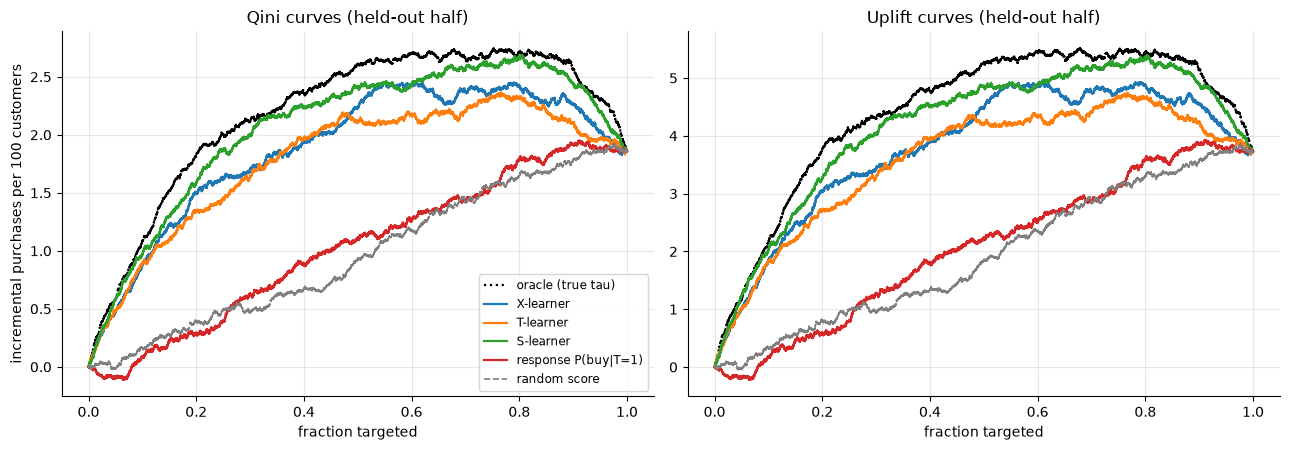

In [10]:
def uplift_qini_curves(y, t, score):
    """Cumulative Qini and uplift curves for a descending-score ranking.

    Returns (frac_targeted, qini, uplift), curves in incremental purchases
    per 100 customers scored."""
    y = np.asarray(y, float)
    t = np.asarray(t, float)
    order = np.argsort(-np.asarray(score), kind="stable")
    y, t = y[order], t[order]
    n = len(y)
    n_t, n_c = np.cumsum(t), np.cumsum(1.0 - t)
    y_t, y_c = np.cumsum(y * t), np.cumsum(y * (1.0 - t))
    frac = np.arange(1, n + 1) / n
    qini = y_t - y_c * n_t / np.maximum(n_c, 1.0)
    uplift = (y_t / np.maximum(n_t, 1.0) - y_c / np.maximum(n_c, 1.0)) * (n_t + n_c)
    return frac, qini / n * 100, uplift / n * 100


def qini_area(y, t, score):
    """Area between the Qini curve and the random diagonal (per 100 customers)."""
    frac, qini, _ = uplift_qini_curves(y, t, score)
    return float(np.mean(qini - qini[-1] * frac))


def auuc(y, t, score):
    """Area under the uplift curve (per 100 customers)."""
    _, _, up = uplift_qini_curves(y, t, score)
    return float(np.mean(up))


scores = {
    "oracle (true tau)": tau_true,
    "X-learner": tau_x,
    "T-learner": tau_t,
    "S-learner": tau_s,
    "response P(buy|T=1)": p1_resp,
    "random score": np.random.default_rng(3).random(n_test),
}
q_oracle = qini_area(y_te, t_te, tau_true)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, sc in scores.items():
    frac, qini, up = uplift_qini_curves(y_te, t_te, sc)
    style = dict(lw=1.6)
    if name == "oracle (true tau)":
        style.update(color="black", ls=":")
    if name == "random score":
        style.update(color="gray", ls="--", lw=1.2)
    axes[0].plot(frac, qini, label=name, **style)
    axes[1].plot(frac, up, label=name, **style)
axes[0].set(title="Qini curves (held-out half)", xlabel="fraction targeted",
            ylabel="incremental purchases per 100 customers")
axes[1].set(title="Uplift curves (held-out half)", xlabel="fraction targeted")
axes[0].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

The learned uplift curves hug the oracle: they buy most of the achievable incremental
sales at 30-40% depth. The response model's curve is the punchline — it starts *flat*
(its top ranks are sure things contributing nothing) and only drifts upward once
persuadables happen to enter, barely beating random targeting at business-relevant
depths. The bump above the endpoint at intermediate depths is the sleeping-dog effect in
reverse: a good ranking defers the negative-$\tau$ customers to the end, so stopping
early beats treating everyone.

**Why ordinary AUC is meaningless here.** AUC scores a ranking against *observed
outcomes*. But uplift is a difference of two conditional probabilities, and a customer
with $p_1 = 0.9, p_0 = 0.9$ (sure thing) outranks $p_1 = 0.35, p_0 = 0.05$ (persuadable)
under any outcome-AUC-optimal model, while the campaign only makes money on the second.
The table makes it concrete: outcome-AUC and uplift quality are almost inversely related
across our scores.

In [11]:
eval_rows = []
for name, sc in scores.items():
    eval_rows.append({
        "score": name,
        "Qini area /100": qini_area(y_te, t_te, sc),
        "share of oracle": qini_area(y_te, t_te, sc) / q_oracle,
        "AUUC /100": auuc(y_te, t_te, sc),
        "AUC for buy (treated arm)": roc_auc_score(y_te[t_te == 1], np.asarray(sc)[t_te == 1]),
    })
eval_tab = pd.DataFrame(eval_rows).set_index("score")
print(eval_tab.round(3).to_string())
print("\nThe response model wins outcome-AUC decisively and loses the uplift ranking;")
print("the oracle tau itself is a mediocre outcome-ranker. AUC answers the wrong question.")

                     Qini area /100  share of oracle  AUUC /100  AUC for buy (treated arm)
score                                                                                     
oracle (true tau)             1.246            1.000      4.395                      0.463
X-learner                     0.933            0.749      3.757                      0.480
T-learner                     0.840            0.674      3.555                      0.481
S-learner                     1.115            0.895      4.124                      0.469
response P(buy|T=1)           0.089            0.071      2.052                      0.695
random score                  0.029            0.023      1.920                      0.497

The response model wins outcome-AUC decisively and loses the uplift ranking;
the oracle tau itself is a mediocre outcome-ranker. AUC answers the wrong question.


## 5. Policy value: from scores to money

Scores are not a policy. The business question is: **treat which customers, at what
budget, for how much profit?** Economics for the voucher:

- margin per purchase: $m = \$25$;
- voucher cost: $c = \$5$, paid only when a *treated* customer buys (redemption).

Expected incremental profit of treating customer $i$:
$\Delta_i = (m - c)\,p_1(x_i) - m\,p_0(x_i) = 20\,p_1 - 25\,p_0$. Two consequences worth
saying out loud in an interview: treating a sure thing has $\Delta \approx -c\,p_0 < 0$
(you pay the discount on sales you already had), and the break-even condition
$\tau > \frac{c}{m - c}\, p_0$ depends on the *level* $p_0$, not just on $\tau > 0$.

We sweep the targeting depth $k$ for three rankings and evaluate two ways:

1. **oracle** — cumulative true $\Delta_i$ (only possible in simulation);
2. **IPS / off-policy estimate** — from the randomized holdout alone, weight each
   observed outcome by inverse propensity ($1/0.5 = 2$):
   $\widehat\Delta(\pi) = \frac{1}{n}\sum_i \pi(x_i)\, 2\left[(m - c)\,y_i T_i - m\, y_i (1 - T_i)\right]$.
   This is exactly the off-policy evaluation used for bandits
   ([../06_bayesian_methods/04_bandits_thompson.ipynb](../06_bayesian_methods/04_bandits_thompson.ipynb)).

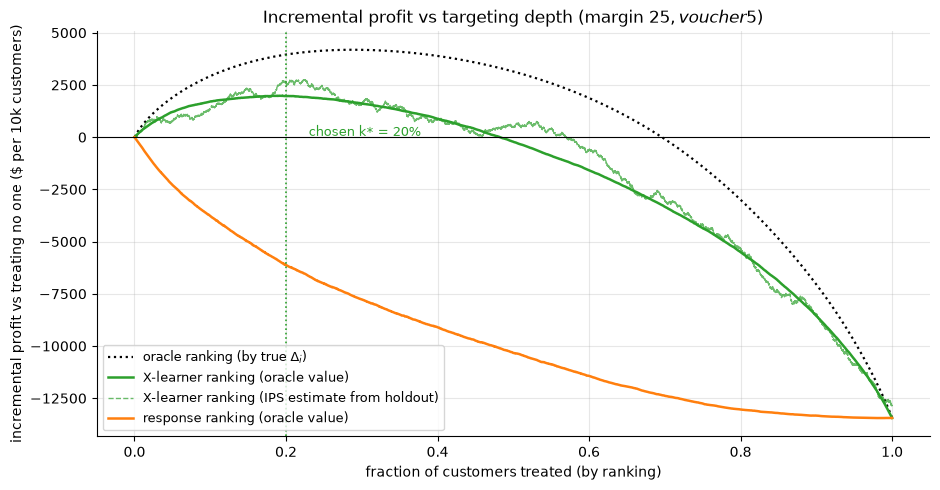

treat-everyone endpoint: -13,444 $ per 10k customers (ATE is positive, yet blanket treatment LOSES money under these economics)


In [12]:
MARGIN, DISC = 25.0, 5.0
delta_true = (MARGIN - DISC) * test["p1"].to_numpy() - MARGIN * test["p0"].to_numpy()
ips_term = 2.0 * np.where(t_te == 1, (MARGIN - DISC) * y_te, -MARGIN * y_te)


def profit_curve(score, values):
    """Cumulative sum of `values` sorted by descending score, in $ per 10k customers."""
    order = np.argsort(-np.asarray(score), kind="stable")
    cum = np.concatenate([[0.0], np.cumsum(values[order]) / len(values) * 10_000])
    frac = np.concatenate([[0.0], np.arange(1, len(values) + 1) / len(values)])
    return frac, cum


frac_x, prof_x = profit_curve(tau_x, delta_true)
_, prof_x_ips = profit_curve(tau_x, ips_term)
_, prof_resp = profit_curve(p1_resp, delta_true)
_, prof_orc = profit_curve(delta_true, delta_true)

# choose k from the *estimated* (IPS) curve on a coarse grid - the honest procedure
grid = np.arange(0.02, 1.0001, 0.02)
pos = (grid * n_test).astype(int)
k_star = grid[np.argmax(prof_x_ips[pos])]
treat_all_profit = prof_x[-1]

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(frac_x, prof_orc, "k:", lw=1.6, label="oracle ranking (by true $\\Delta_i$)")
ax.plot(frac_x, prof_x, color="tab:green", lw=1.8, label="X-learner ranking (oracle value)")
ax.plot(frac_x, prof_x_ips, color="tab:green", ls="--", lw=1.0, alpha=0.7,
        label="X-learner ranking (IPS estimate from holdout)")
ax.plot(frac_x, prof_resp, color="tab:orange", lw=1.8, label="response ranking (oracle value)")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(k_star, color="tab:green", ls=":", lw=1.2)
ax.annotate(f"chosen k* = {k_star:.0%}", (k_star, ax.get_ylim()[1] * 0.05),
            xytext=(k_star + 0.03, 60), fontsize=9, color="tab:green")
ax.set(title=f"Incremental profit vs targeting depth (margin ${MARGIN:.0f}, voucher ${DISC:.0f})",
       xlabel="fraction of customers treated (by ranking)",
       ylabel="incremental profit vs treating no one ($ per 10k customers)")
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()
print(f"treat-everyone endpoint: {treat_all_profit:+,.0f} $ per 10k customers "
      f"(ATE is positive, yet blanket treatment LOSES money under these economics)")

In [13]:
def policy_eval(pi):
    """Oracle and IPS incremental profit of boolean policy pi, $ per 10k customers."""
    oracle = delta_true[pi].sum() / n_test * 10_000
    terms = np.where(pi, ips_term, 0.0)
    return oracle, terms.mean() * 10_000, terms.std(ddof=1) / np.sqrt(n_test) * 10_000


rank_x = np.argsort(-tau_x, kind="stable")
pi_x = np.zeros(n_test, bool)
pi_x[rank_x[:int(k_star * n_test)]] = True
pi_resp30 = np.zeros(n_test, bool)
pi_resp30[np.argsort(-p1_resp, kind="stable")[:k30]] = True

rows = []
for name, pi in {
    "treat no one": np.zeros(n_test, bool),
    "treat everyone": np.ones(n_test, bool),
    "response model, top 30%": pi_resp30,
    f"X-learner, top {k_star:.0%}": pi_x,
    "oracle rule (true delta > 0)": delta_true > 0,
}.items():
    oracle, est, se_ips = policy_eval(pi)
    rows.append({"policy": name, "share treated": pi.mean(),
                 "oracle $/10k": oracle, "IPS estimate $/10k": est, "IPS SE": se_ips})
print(pd.DataFrame(rows).set_index("policy").round(1).to_string())

                              share treated  oracle $/10k  IPS estimate $/10k    IPS SE
policy                                                                                 
treat no one                          0.000         0.000               0.000     0.000
treat everyone                        1.000   -13,444.400         -12,833.300 1,672.900
response model, top 30%               0.300    -7,770.900          -7,270.000 1,118.900
X-learner, top 20%                    0.200     1,970.100           2,583.300   700.500
oracle rule (true delta > 0)          0.300     4,186.000           3,883.300   759.500


The ATE-positive campaign is *unprofitable* rolled out blindly, the response policy burns
money at its standard budget, and the uplift policy captures most of what the oracle rule
achieves. Notes a senior candidate should attach:

- **$k^*$ was chosen on the same holdout used to report the IPS value** — a small
  optimism bias. In practice: pick $k$ on a validation split (or by cross-validated Qini),
  report value on a final untouched holdout, and confirm with the next campaign's
  randomized slice.
- The IPS estimate is unbiased but noisy (SE of roughly $\pm$ a few hundred dollars per
  10k here); doubly robust versions reduce variance — same idea as AIPW in
  [02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb).
- Top-$k$ by $\hat\tau$ is not the optimal *shape* of policy under these economics — the
  break-even threshold depends on $\hat p_0$ too. Exercise 3 builds the better rule.

## 6. Pitfalls

### 6.1 Learners invent segments where none exist

Uplift models are fit to an *unobservable* target, so nothing in the training loss stops
them from manufacturing heterogeneity out of binomial noise. Simulate the same customer
base with a **flat** $\tau = +0.04$ for everyone, fit a flexible T-learner, and watch it
find "segments" — then watch honest out-of-sample Qini expose them.

true tau: +0.040 for EVERY customer (no heterogeneity)
predicted tau, training data: sd = 0.359, 64% of customers 'off' by >10pp
Qini area, in-sample     : +11.21 per 100 customers  <- spectacular, and fake
Qini area, out-of-sample : -0.01 per 100 customers  <- the truth: nothing to rank


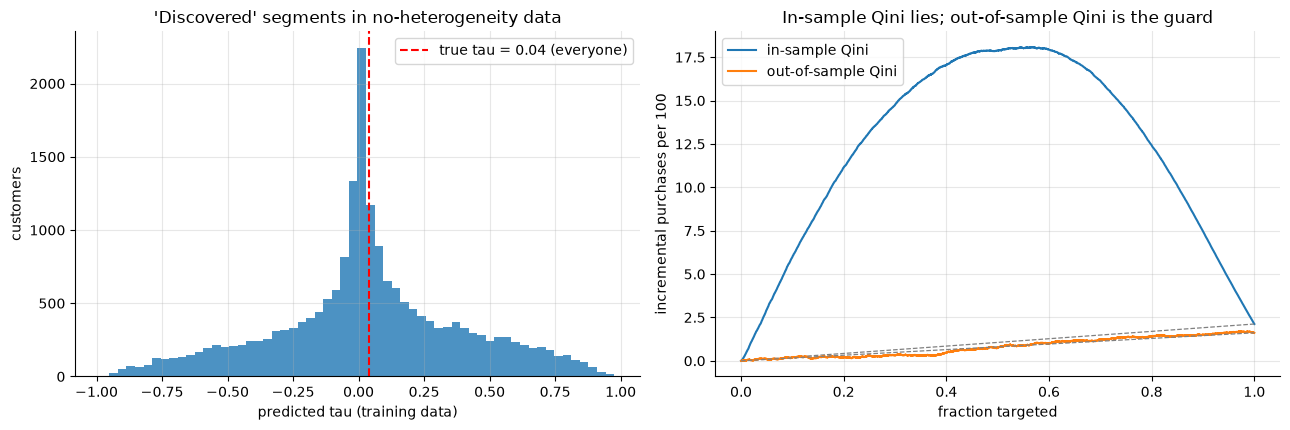

In [14]:
rng_nh = np.random.default_rng(7)
pop_nh = make_population(40_000, rng_nh, heterogeneity=False)
df_nh = run_rct(pop_nh, rng_nh)
perm_nh = rng_nh.permutation(len(df_nh))
tr_nh = df_nh.iloc[perm_nh[:20_000]].reset_index(drop=True)
te_nh = df_nh.iloc[perm_nh[20_000:]].reset_index(drop=True)

flex = dict(n_estimators=400, learning_rate=0.1, num_leaves=63, min_child_samples=5,
            random_state=42, n_jobs=1, verbose=-1)
t1 = tr_nh["treated"] == 1
m1_nh = lgb.LGBMClassifier(**flex).fit(tr_nh.loc[t1, X_COLS], tr_nh.loc[t1, "buy"])
m0_nh = lgb.LGBMClassifier(**flex).fit(tr_nh.loc[~t1, X_COLS], tr_nh.loc[~t1, "buy"])

tau_nh_in = (m1_nh.predict_proba(tr_nh[X_COLS])[:, 1]
             - m0_nh.predict_proba(tr_nh[X_COLS])[:, 1])
tau_nh_out = (m1_nh.predict_proba(te_nh[X_COLS])[:, 1]
              - m0_nh.predict_proba(te_nh[X_COLS])[:, 1])

print(f"true tau: +0.040 for EVERY customer (no heterogeneity)")
print(f"predicted tau, training data: sd = {tau_nh_in.std():.3f}, "
      f"{(np.abs(tau_nh_in - 0.04) > 0.10).mean():.0%} of customers 'off' by >10pp")

q_in = qini_area(tr_nh["buy"], tr_nh["treated"], tau_nh_in)
q_out = qini_area(te_nh["buy"], te_nh["treated"], tau_nh_out)
print(f"Qini area, in-sample     : {q_in:+.2f} per 100 customers  <- spectacular, and fake")
print(f"Qini area, out-of-sample : {q_out:+.2f} per 100 customers  <- the truth: nothing to rank")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].hist(tau_nh_in, bins=60, alpha=0.8)
axes[0].axvline(0.04, color="red", ls="--", label="true tau = 0.04 (everyone)")
axes[0].set(title="'Discovered' segments in no-heterogeneity data",
            xlabel="predicted tau (training data)", ylabel="customers")
axes[0].legend()
for lab, (dat, tau_hat) in {"in-sample": (tr_nh, tau_nh_in),
                            "out-of-sample": (te_nh, tau_nh_out)}.items():
    frac, qini, _ = uplift_qini_curves(dat["buy"], dat["treated"], tau_hat)
    axes[1].plot(frac, qini, label=f"{lab} Qini")
    axes[1].plot(frac, qini[-1] * frac, ls="--", lw=0.9, color="gray")
axes[1].set(title="In-sample Qini lies; out-of-sample Qini is the guard",
            xlabel="fraction targeted", ylabel="incremental purchases per 100")
axes[1].legend()
plt.tight_layout()
plt.show()

The in-sample Qini is enormous because the flexible arm models partially memorize
outcomes: ranking by $\hat\mu_1 - \hat\mu_0$ in-sample puts treated buyers and control
non-buyers on top — a rigged comparison. Out-of-sample the curve collapses onto the
random diagonal. **Every uplift number you quote must be out-of-sample**, and a flat
out-of-sample Qini is a legitimate finding: "this treatment has no exploitable
heterogeneity — treat by the average effect and the economics."

### 6.2 Confounded data poisons both the model *and* its evaluation

Meta-learners consume $(x, t, y)$ triples and will happily run on observational logs —
say, last year's campaign where reps offered the voucher to customers who *looked ready
to buy* (an unobserved intent signal $u$). Then $E[y \mid t{=}1, x] - E[y \mid t{=}0, x]$
identifies nothing causal: the same $u$ that drove targeting drives conversion. Worse,
the decile "validation" on held-out *confounded* data reproduces the same bias — the
model looks great precisely because it is wrong.

In [15]:
rng_cf = np.random.default_rng(11)
pop_cf = make_population(40_000, rng_cf)
u = rng_cf.normal(0.0, 1.0, len(pop_cf))                 # unobserved purchase intent
p0_cf = expit(logit(pop_cf["p0"].to_numpy()) + 1.1 * u)  # intent lifts baseline conversion
p1_cf = np.clip(p0_cf + pop_cf["tau"].to_numpy(), 0.002, 0.985)
t_cf = rng_cf.binomial(1, expit(-0.5 + 1.4 * u))         # reps target visible intent
y_cf = (rng_cf.random(len(pop_cf))
        < np.where(t_cf == 1, p1_cf, p0_cf)).astype(int)
df_cf = pop_cf[X_COLS].copy().assign(treated=t_cf, buy=y_cf, tau=p1_cf - p0_cf)

perm_cf = rng_cf.permutation(len(df_cf))
tr_cf = df_cf.iloc[perm_cf[:20_000]].reset_index(drop=True)
te_cf = df_cf.iloc[perm_cf[20_000:]].reset_index(drop=True)
c1 = tr_cf["treated"] == 1
m1_cf = new_clf().fit(tr_cf.loc[c1, X_COLS], tr_cf.loc[c1, "buy"])
m0_cf = new_clf().fit(tr_cf.loc[~c1, X_COLS], tr_cf.loc[~c1, "buy"])
tau_cf_hat = (m1_cf.predict_proba(te_cf[X_COLS])[:, 1]
              - m0_cf.predict_proba(te_cf[X_COLS])[:, 1])

naive_dim = (df_cf.loc[df_cf["treated"] == 1, "buy"].mean()
             - df_cf.loc[df_cf["treated"] == 0, "buy"].mean())
print(f"treated share: {df_cf['treated'].mean():.1%}   true ATE: {df_cf['tau'].mean():+.3f}")
print(f"naive diff-in-means           : {naive_dim:+.3f}  <- confounded")
print(f"mean T-learner tau-hat (OOS)  : {tau_cf_hat.mean():+.3f}  <- inherits the confounding")

quint = pd.qcut(tau_cf_hat, 5, labels=False) + 1
vtab = (te_cf.assign(q=quint)
        .groupby("q")
        .apply(lambda d: pd.Series({
            "obs 'uplift' (confounded)": d.loc[d["treated"] == 1, "buy"].mean()
                                         - d.loc[d["treated"] == 0, "buy"].mean(),
            "true mean tau": d["tau"].mean()}), include_groups=False))
print("\nquintiles of predicted uplift on held-out CONFOUNDED data:")
print(vtab.round(3).to_string())
print("\nEvery quintile's 'observed uplift' is inflated by the same selection effect ->")
print("out-of-sample validation on confounded data cannot detect the problem.")

treated share: 41.1%   true ATE: +0.031
naive diff-in-means           : +0.229  <- confounded
mean T-learner tau-hat (OOS)  : +0.234  <- inherits the confounding

quintiles of predicted uplift on held-out CONFOUNDED data:
   obs 'uplift' (confounded)  true mean tau
q                                          
1                      0.150         -0.037
2                      0.190          0.007
3                      0.214          0.027
4                      0.271          0.052
5                      0.308          0.103

Every quintile's 'observed uplift' is inflated by the same selection effect ->
out-of-sample validation on confounded data cannot detect the problem.


Held-out data does not help because the *holdout is confounded too* — the observed
"uplift" in every quintile is far above the true effect. The fixes are the standard
causal ones: run a randomized experiment (even a small persistent holdout gives clean
evaluation data), or bring the full observational toolkit — propensity weighting inside
the learner (DR-/R-learner), overlap diagnostics, sensitivity analysis
([02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb)). An
uplift model is a causal model and inherits every causal assumption.

### 6.3 Sample-size hunger

Uplift is a difference of two conditional means, so its estimation noise is roughly the
*sum* of the two arms' variances: detecting a difference between arms needs about
**4x the sample** that estimating one arm's rate needs, before you even slice by $x$.
CATE estimation slices implicitly and pays the price everywhere. We shrink the training
set and watch the T-learner degrade against the fixed held-out half.

          MSE  qini_share
n_train                  
1000    0.069       0.416
3000    0.070       0.374
10000   0.036       0.484
30000   0.014       0.649


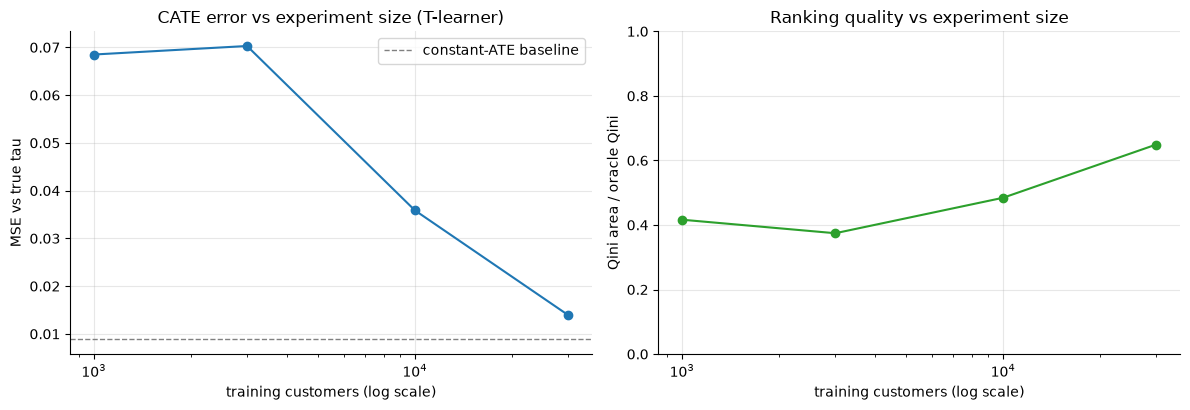

In [16]:
rng_ss = np.random.default_rng(5)
perm_ss = rng_ss.permutation(len(train))
size_rows = []
for size in [1_000, 3_000, 10_000, 30_000]:
    for r in range(3 if 3 * size <= len(train) else 1):
        sub = train.iloc[perm_ss[r * size:(r + 1) * size]]
        s1 = sub["treated"] == 1
        kw = dict(n_estimators=300, learning_rate=0.05, num_leaves=31,
                  min_child_samples=50, random_state=42, n_jobs=1, verbose=-1)
        f1 = lgb.LGBMClassifier(**kw).fit(sub.loc[s1, X_COLS], sub.loc[s1, "buy"])
        f0 = lgb.LGBMClassifier(**kw).fit(sub.loc[~s1, X_COLS], sub.loc[~s1, "buy"])
        th = f1.predict_proba(test[X_COLS])[:, 1] - f0.predict_proba(test[X_COLS])[:, 1]
        size_rows.append({"n_train": size,
                          "MSE": np.mean((th - tau_true) ** 2),
                          "qini_share": qini_area(y_te, t_te, th) / q_oracle})
size_tab = pd.DataFrame(size_rows).groupby("n_train").mean()
print(size_tab.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(size_tab.index, size_tab["MSE"], "o-")
axes[0].axhline(np.var(tau_true), color="gray", ls="--", lw=1,
                label="constant-ATE baseline")
axes[0].set(xscale="log", title="CATE error vs experiment size (T-learner)",
            xlabel="training customers (log scale)", ylabel="MSE vs true tau")
axes[0].legend()
axes[1].plot(size_tab.index, size_tab["qini_share"], "o-", color="tab:green")
axes[1].set(xscale="log", ylim=(0, 1),
            title="Ranking quality vs experiment size",
            xlabel="training customers (log scale)", ylabel="Qini area / oracle Qini")
plt.tight_layout()
plt.show()

With 1,000 customers (500 per arm) the T-learner barely improves on predicting the ATE
for everyone; usable person-level uplift only emerges in the tens of thousands. Rule of
thumb before promising an uplift model: could the experiment even *detect* the difference
between your intended top and bottom deciles as a two-sample test? Power that calculation
like any A/B test ([../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb));
if the answer is no, ship segment-level uplift (or nothing) instead of person-level scores.

## 7. Practical notes

- **Data requirements come first.** The clean recipe is: randomize (or keep a persistent
  random holdout slice in every campaign), train uplift on the randomized data, evaluate
  on a further untouched randomized slice. Observational logs from a previous *targeted*
  campaign are confounded by the previous targeting rule (Section 6.2) — a feedback loop
  where each model poisons the next model's training data.
- **Keep a global holdout in production.** A never-treated (and an always-random) slice
  gives you honest Qini refreshes, drift detection for $\tau(x)$
  ([../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb)),
  and the realized-value readout finance will ask for.
- **Sample-size hunger is the binding constraint** more often than model choice: the 4x
  rule plus implicit slicing (Section 6.3). Meta-learner choice matters most when data
  are limited or arms imbalanced (X-, R-, DR-learners); with huge balanced experiments
  even a T-learner is fine.
- **Contextual bandits are the online version of this notebook.** An uplift policy is
  one-shot off-policy learning from a uniformly-random logged policy, and our IPS profit
  estimate is exactly off-policy evaluation. When treatments repeat and effects drift, a
  contextual bandit (e.g. Thompson sampling,
  [../06_bayesian_methods/04_bandits_thompson.ipynb](../06_bayesian_methods/04_bandits_thompson.ipynb))
  allocates the experiment adaptively instead of 50/50; batch campaigns with monthly
  cadence are where offline uplift modeling remains standard.
- **In production use a library, in interviews build from scratch.** `CausalML` (Uber)
  and `EconML` (Microsoft) ship meta-learners, uplift trees/forests and DR/R-learners;
  `scikit-uplift` ships the metrics. The from-scratch versions above are the expected
  interview artifact — and LightGBM tuning itself is covered in
  [../04_ml_tabular/01_gradient_boosting_mastery.ipynb](../04_ml_tabular/01_gradient_boosting_mastery.ipynb).

## 8. Interview corner

**1. "We can give a \$5 discount to 20% of customers. Who should get it?"**
Frame as uplift, not response: value = $\sum \tau_i$ over the treated set, cost depends on
redemption. Propose an initial randomized campaign, train an uplift model (X-learner or
causal forest), validate with out-of-sample Qini/decile charts, then target by expected
incremental *profit* $(m - c)\hat p_1 - m \hat p_0$, not raw $\hat\tau$. Mention the four
segments and that negative-$\tau$ customers should be actively excluded.

**2. "How do you evaluate an uplift model offline when you never observe individual
effects?"** Randomized holdout + group-level counterfactuals: uplift decile chart with
CIs (ranking + calibration), Qini/uplift curves and AUUC, out-of-sample only. State your
Qini convention. If the logged data came from a targeted policy, offline evaluation is
biased no matter the metric — you need the randomization (or IPW with known logging
propensities).

**3. "Marketing wants to target the customers most likely to buy. Critique."**
The ranking objective is wrong: high $\hat p_1$ selects sure things (discount cost, zero
incremental sales) and doesn't avoid sleeping dogs (negative effect). Show the segment
framework; concede the edge case where $\tau(x)$ happens to increase with $p_1(x)$ —
then response targeting accidentally works, but you only know that by measuring uplift.
Offer the cheap upgrade: keep their model, add a randomized holdout, and quantify the
incremental value per decile of their ranking.

**4. "S vs T vs X-learner — when does each win?"** S pools everything (good with tiny
effects/data) but regularization biases $\hat\tau$ toward 0; T is unbiased-by-construction
but noisy (difference of two models) and wasteful; X models $\tau(x)$ directly on imputed
effects and blends by propensity — strongest with imbalanced arms and smooth $\tau$.
Name-drop R-/DR-learners (orthogonalized, cross-fitted) as the production standard.

**5. "Why not just use AUC to pick the best uplift model?"** AUC measures ranking of
observed outcomes; uplift is a difference of counterfactual probabilities. A perfect
outcome-ranker can be a useless (even harmful) uplift-ranker — demonstrated above where
the response model wins AUC by a wide margin and loses Qini decisively. Metrics must be
computed against group-level counterfactuals (Qini/AUUC), not labels.

**6. "Your model says some customers have negative uplift. Do you believe it?"**
Maybe — sleeping dogs are real (discount fatigue, brand dilution, retention calls that
remind people to cancel). But negative tails are also the first thing noise
heterogeneity fabricates (Section 6.1). Checks: does the bottom decile show significantly
negative *observed* uplift out-of-sample; is it stable across refits/folds; is there a
plausible mechanism? If yes, excluding them is often the single most profitable model
decision.

**7. "How much data do you need for an uplift model?"** Work backwards from the decile
chart: to see a $\Delta\tau$ of a few pp between top and bottom deciles you need each
decile to power a two-proportion test at that MDE — with the 4x penalty for differencing
arms. That lands in the tens of thousands per campaign for typical conversion rates.
Below that, estimate uplift for a handful of predefined segments instead.

**8. "The model is live. How do you know it keeps working?"** Persistent randomized
holdout (both a never-treat and a random-treat slice), scheduled out-of-sample Qini and
realized incremental profit against it, monitoring for drift in score distribution and
in $\hat\tau$ calibration, periodic retraining on the fresh randomized data — never on
the model's own targeted traffic.

## 9. Key takeaways

- Campaign value is $\sum_{\text{targeted}} \tau_i$; response models rank by $p_1$ and
  therefore optimize the wrong objective — wasting budget on sure things and stepping on
  sleeping dogs.
- The four segments (persuadable / sure thing / lost cause / sleeping dog) are the
  vocabulary of every uplift discussion; only persuadables pay for the campaign, and
  negative uplift is a real phenomenon, not a modeling artifact.
- S-, T-, X-learners reduce CATE estimation to supervised learning; their biases differ
  (S: shrinkage toward 0; T: two-model noise; X: direct $\tau$ modeling, propensity
  blend) and all of them beat nothing only with enough randomized data.
- Evaluation is by group-level counterfactuals on a randomized holdout: decile charts
  with CIs, Qini/uplift curves, AUUC. Ordinary AUC on outcomes is meaningless for uplift.
- Always evaluate out-of-sample: in-sample Qini rewards memorization and will "validate"
  segments invented from pure noise.
- Out-of-sample evaluation does *not* fix confounded training data — on observational
  logs both the model and its validation inherit the same bias. Uplift modeling needs
  randomization or a defended unconfoundedness argument.
- Scores become policies through economics: treat when
  $(m - c)\,\hat p_1 - m\,\hat p_0 > 0$; a positive-ATE campaign can lose money if
  blanket-deployed, and the profit-maximizing depth $k^*$ comes from an (IPS-estimated)
  profit curve, chosen on data not reused for the final claim.
- Uplift modeling is the offline, one-shot corner of policy learning; contextual bandits
  are its online generalization.

## 10. Exercises

**Exercise 1 — the class-transformation trick.** With 50/50 randomization, define
$Z_i = Y_i T_i + (1 - Y_i)(1 - T_i)$ ("outcome agrees with treatment"). Show that
$P(Z{=}1 \mid x) = \tfrac{1}{2}\left(1 + \tau(x)\right)$, so a *single* classifier for
$Z$ yields $\hat\tau(x) = 2\hat P(Z{=}1\mid x) - 1$. Implement it and compare MSE and
Qini share against the X-learner. When does this trick break?

**Exercise 2 — imbalanced arms.** Re-run the experiment with only 10% treated (a
realistic constraint when treatment is expensive). Compare T- and X-learner MSE, using
the propensity blend $\hat\tau = e\,\hat\tau_0 + (1 - e)\,\hat\tau_1$ with $e = 0.1$.
Explain *why* the X-learner's weighting helps here.

**Exercise 3 — a better policy than top-k.** Using the T-learner's arm models, build the
rule "treat iff $(m - c)\,\hat p_1(x) - m\,\hat p_0(x) > 0$" and compare its oracle
profit against the top-$k^*$ uplift policy from Section 5 and the oracle rule. Why can a
worse *ranker* still yield a better *policy* here?

In [17]:
# --- Solution 1: class transformation ---
# P(Z=1|x) = P(Y=1|T=1,x) P(T=1) + P(Y=0|T=0,x) P(T=0) = 0.5 p1 + 0.5 (1 - p0)
#          = 0.5 (1 + tau)   =>   tau = 2 P(Z=1|x) - 1
z_train = (train["buy"] * train["treated"]
           + (1 - train["buy"]) * (1 - train["treated"]))
z_model = new_clf().fit(train[X_COLS], z_train)
tau_z = 2.0 * z_model.predict_proba(test[X_COLS])[:, 1] - 1.0

print("class-transformation vs X-learner (held-out half):")
for name, th in {"Z-model": tau_z, "X-learner": tau_x}.items():
    print(f"  {name:<10} MSE = {np.mean((th - tau_true) ** 2):.4f}   "
          f"Qini share of oracle = {qini_area(y_te, t_te, th) / q_oracle:.2f}")
print("One model, no counterfactual plumbing - a strong baseline. It breaks when")
print("P(T=1) != 1/2 (needs reweighting by the propensity) and its single-model")
print("variance grows fast when tau is small relative to outcome noise.")

class-transformation vs X-learner (held-out half):
  Z-model    MSE = 0.0160   Qini share of oracle = 0.52
  X-learner  MSE = 0.0084   Qini share of oracle = 0.75
One model, no counterfactual plumbing - a strong baseline. It breaks when
P(T=1) != 1/2 (needs reweighting by the propensity) and its single-model
variance grows fast when tau is small relative to outcome noise.


In [18]:
# --- Solution 2: imbalanced arms (10% treated) ---
rng_ex2 = np.random.default_rng(21)
pop2 = make_population(40_000, rng_ex2)
df2 = run_rct(pop2, rng_ex2, p_treat=0.10)
perm2 = rng_ex2.permutation(len(df2))
tr2 = df2.iloc[perm2[:20_000]].reset_index(drop=True)
te2 = df2.iloc[perm2[20_000:]].reset_index(drop=True)
tau2_true = te2["tau"].to_numpy()
kw2 = dict(n_estimators=300, learning_rate=0.05, num_leaves=31,
           min_child_samples=30, random_state=42, n_jobs=1, verbose=-1)

i1 = tr2["treated"] == 1
print(f"treated in training data: {i1.sum():,} of {len(tr2):,}")
g1 = lgb.LGBMClassifier(**kw2).fit(tr2.loc[i1, X_COLS], tr2.loc[i1, "buy"])
g0 = lgb.LGBMClassifier(**kw2).fit(tr2.loc[~i1, X_COLS], tr2.loc[~i1, "buy"])
tau_t2 = g1.predict_proba(te2[X_COLS])[:, 1] - g0.predict_proba(te2[X_COLS])[:, 1]

d1_2 = tr2.loc[i1, "buy"].to_numpy() - g0.predict_proba(tr2.loc[i1, X_COLS])[:, 1]
d0_2 = g1.predict_proba(tr2.loc[~i1, X_COLS])[:, 1] - tr2.loc[~i1, "buy"].to_numpy()
h1 = lgb.LGBMRegressor(**kw2).fit(tr2.loc[i1, X_COLS], d1_2)
h0 = lgb.LGBMRegressor(**kw2).fit(tr2.loc[~i1, X_COLS], d0_2)
e2 = 0.10
tau_x2 = e2 * h0.predict(te2[X_COLS]) + (1 - e2) * h1.predict(te2[X_COLS])

for name, th in {"T-learner": tau_t2, "X-learner": tau_x2}.items():
    print(f"  {name:<10} MSE = {np.mean((th - tau2_true) ** 2):.4f}   "
          f"corr = {np.corrcoef(th, tau2_true)[0, 1]:.3f}")
print("With 10% treated, mu1-hat is the weak link. The X-learner puts weight 0.9 on")
print("tau1-hat - fit on D1 = Y - mu0-hat(x) for treated units, which leans on the")
print("control model trained on 18k rows - so mu1-hat's noise is largely bypassed.")
print("The T-learner subtracts the noisy mu1-hat directly for every prediction.")

treated in training data: 1,976 of 20,000


  T-learner  MSE = 0.0435   corr = 0.329
  X-learner  MSE = 0.0339   corr = 0.386
With 10% treated, mu1-hat is the weak link. The X-learner puts weight 0.9 on
tau1-hat - fit on D1 = Y - mu0-hat(x) for treated units, which leans on the
control model trained on 18k rows - so mu1-hat's noise is largely bypassed.
The T-learner subtracts the noisy mu1-hat directly for every prediction.


In [19]:
# --- Solution 3: economics-aware rule beats top-k by tau ---
p1_hat = mu1.predict_proba(test[X_COLS])[:, 1]
p0_hat = mu0.predict_proba(test[X_COLS])[:, 1]
delta_hat = (MARGIN - DISC) * p1_hat - MARGIN * p0_hat

for name, pi in {
    f"X-learner top {k_star:.0%} by tau-hat": pi_x,
    "rule: (m-c) p1-hat - m p0-hat > 0": delta_hat > 0,
    "oracle rule (true delta > 0)": delta_true > 0,
}.items():
    oracle, est, se_ips = policy_eval(pi)
    print(f"  {name:<36} treats {pi.mean():5.1%}   oracle profit = {oracle:+8,.0f} $/10k")
print("The rule targets by estimated incremental PROFIT, so it declines persuadables")
print("whose p0 is too high for the voucher to pay off and admits marginal customers")
print("that a pure tau ranking mis-prioritizes; it also chooses its own treated share")
print("instead of inheriting a fixed k. Better economics can beat a better ranker.")

  X-learner top 20% by tau-hat         treats 20.0%   oracle profit =   +1,970 $/10k
  rule: (m-c) p1-hat - m p0-hat > 0    treats 40.5%   oracle profit =   +1,274 $/10k
  oracle rule (true delta > 0)         treats 28.8%   oracle profit =   +4,186 $/10k
The rule targets by estimated incremental PROFIT, so it declines persuadables
whose p0 is too high for the voucher to pay off and admits marginal customers
that a pure tau ranking mis-prioritizes; it also chooses its own treated share
instead of inheriting a fixed k. Better economics can beat a better ranker.
